# 08 · Experiment E3: which encoder, and at what cost? (task T24, runs R16 to R21)

**RQ3.** With only 252 training chips, is a light pretrained encoder better than a small network trained from nothing? Everything else is the frozen default (VV + VH + ratio input, BCE + Dice loss):

| Config | Encoder | Runs |
|---|---|---|
| Scratch U-Net | 5 levels, 16–256 filters, random initial weights | R16, R17, R18 |
| Default | MobileNetV2, random initial weights | R01, R02, R03 (shared) |
| MobileNetV2 + ImageNet | MobileNetV2 starting from ImageNet weights | R19, R20, R21 |

ImageNet weights were learned on ordinary colour photographs scaled to [−1, 1]. The standardised radar channels look nothing like that, so whether the weights still help is part of the question.

The second half of the notebook measures what each encoder **costs**: parameters, time per training step, time per predicted chip and peak GPU memory.

In [1]:
import json
import sys
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))
import src  # noqa: F401  (must come before TensorFlow: switches on the XLA compile cache)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import analysis, viz
from src.config import STUDIES, load_config, run_table, runs_of
from src.runner import check_frozen, run_benchmark, run_evaluation, run_many

viz.use_style()
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
print("training and scoring code is identical to the frozen tag 'defaults-frozen' (commit %s)" % check_frozen()[:7])

STUDY = "E3"
CONFIGS = STUDIES[STUDY]["configs"]
pd.DataFrame([r for r in run_table() if r["config_name"] in CONFIGS]).fillna({"encoder": "mobilenetv2"}).set_index("run_id")

training and scoring code is identical to the frozen tag 'defaults-frozen' (commit 43821af)


,config_name,study,seed,encoder
run_id,,,,
R01,Default,"E1, E2, E3 (shared)",0,mobilenetv2
R02,Default,"E1, E2, E3 (shared)",1,mobilenetv2
R03,Default,"E1, E2, E3 (shared)",2,mobilenetv2
R16,Scratch U-Net,E3,0,scratch
R17,Scratch U-Net,E3,1,scratch
R18,Scratch U-Net,E3,2,scratch
R19,MobileNetV2 + ImageNet,E3,0,mobilenetv2_imagenet
R20,MobileNetV2 + ImageNet,E3,1,mobilenetv2_imagenet
R21,MobileNetV2 + ImageNet,E3,2,mobilenetv2_imagenet


## 1. Train and score R16 to R21

In [2]:
results = run_many(["R16", "R17", "R18", "R19", "R20", "R21"])


[R16 was trained on 2026-11-11 15:13 UTC; this is its saved log]
R16: Scratch U-Net | encoder scratch | channels vv_vh_ratio | loss bce_dice | seed 0 | 1,967,041 parameters | mixed_float16
epoch  1/60 | loss 0.9766  iou 0.4289 | val_loss 3.0268  val_iou 0.2949 | lr 1.0e-03 |  66.5s *
epoch  2/60 | loss 0.8123  iou 0.4577 | val_loss 2.4773  val_iou 0.1929 | lr 1.0e-03 |   6.0s
epoch  3/60 | loss 0.7332  iou 0.4675 | val_loss 0.4988  val_iou 0.5772 | lr 1.0e-03 |   5.9s *
epoch  4/60 | loss 0.6658  iou 0.5064 | val_loss 0.5544  val_iou 0.5668 | lr 1.0e-03 |   5.9s
epoch  5/60 | loss 0.6856  iou 0.4617 | val_loss 0.4910  val_iou 0.6162 | lr 1.0e-03 |   5.9s *
epoch  6/60 | loss 0.6713  iou 0.4818 | val_loss 0.4908  val_iou 0.5906 | lr 1.0e-03 |   5.9s
epoch  7/60 | loss 0.6515  iou 0.4977 | val_loss 0.4948  val_iou 0.5912 | lr 1.0e-03 |   6.0s
epoch  8/60 | loss 0.6139  iou 0.5348 | val_loss 0.4411  val_iou 0.6252 | lr 1.0e-03 |   6.0s *
epoch  9/60 | loss 0.6262  iou 0.5219 | val_loss 0

## 2. Results

One row per run. Validation IoU is the score the checkpoint was chosen by; test and Bolivia were scored once, after training.

In [3]:
runs = analysis.runs_table()
study_runs = runs[runs["Config"].isin(CONFIGS)]
study_runs[["Run ID", "Config", "Seed", "Status", "Epochs trained", "Best epoch", "Val IoU (best)", "Test IoU",
            "Test precision", "Test recall", "Bolivia IoU", "Sec per epoch"]].set_index("Run ID")

,Config,Seed,Status,Epochs trained,Best epoch,Val IoU (best),Test IoU,Test precision,Test recall,Bolivia IoU,Sec per epoch
Run ID,,,,,,,,,,,
R01,Default,0,Finished,39.0000,24.0000,0.6282,0.6681,0.8520,0.7558,0.6547,8.6400
R02,Default,1,Finished,32.0000,17.0000,0.6449,0.6640,0.8437,0.7571,0.6213,8.4400
R03,Default,2,Finished,34.0000,19.0000,0.6435,0.6674,0.8135,0.7880,0.6347,8.5900
R16,Scratch U-Net,0,Finished,46.0000,31.0000,0.6493,0.6614,0.7936,0.7988,0.7264,6.3000
R17,Scratch U-Net,1,Finished,45.0000,30.0000,0.6422,0.6612,0.7935,0.7987,0.6959,6.3000
R18,Scratch U-Net,2,Finished,20.0000,5.0000,0.6312,0.6435,0.7950,0.7715,0.5918,6.2500
R19,MobileNetV2 + ImageNet,0,Finished,60.0000,47.0000,0.6697,0.6613,0.8470,0.7511,0.5351,8.2500
R20,MobileNetV2 + ImageNet,1,Finished,44.0000,29.0000,0.6675,0.6666,0.8442,0.7601,0.5242,8.3000
R21,MobileNetV2 + ImageNet,2,Finished,49.0000,34.0000,0.6558,0.6580,0.8479,0.7460,0.4985,8.6100


Mean ± standard deviation over the three seeds (the two threshold baselines, single deterministic runs, are shown for reference):

In [4]:
analysis.study_table(STUDY, analysis.summary_table(runs))

,Finished runs,Val IoU (best),Test IoU,Test precision,Test recall,Bolivia IoU
Config,,,,,,
Otsu (E0),1,0.388,0.433,0.483,0.809,0.653
Tuned VH threshold,1,0.492,0.524,0.747,0.637,0.531
Scratch U-Net,3,0.641 ± 0.009,0.655 ± 0.010,0.794 ± 0.001,0.790 ± 0.016,0.671 ± 0.071
Default,3,0.639 ± 0.009,0.667 ± 0.002,0.836 ± 0.020,0.767 ± 0.018,0.637 ± 0.017
MobileNetV2 + ImageNet,3,0.664 ± 0.007,0.662 ± 0.004,0.846 ± 0.002,0.752 ± 0.007,0.519 ± 0.019


**Is a difference real?** The project's rule: a gap between two configs counts only if it is larger than the seed-to-seed standard deviation.

In [5]:
gaps = analysis.gap_table(STUDY, runs)
gaps.to_csv(ROOT / "results" / f"{STUDY}_gaps.csv", index=False)
gaps.set_index(["Metric", "A", "B"])

,,,Mean A,Mean B,Gap (A - B),Larger std,Gap / std,Gap larger than std,Welch p
Metric,A,B,,,,,,,
Test IoU,Scratch U-Net,Default,0.6554,0.6665,-0.0111,0.0103,1.0824,True,0.1975
Bolivia IoU,Scratch U-Net,Default,0.6714,0.6369,0.0345,0.0706,0.4886,False,0.4892
Test IoU,Scratch U-Net,MobileNetV2 + ImageNet,0.6554,0.6620,-0.0066,0.0103,0.6397,False,0.3904
Bolivia IoU,Scratch U-Net,MobileNetV2 + ImageNet,0.6714,0.5193,0.1521,0.0706,2.1551,True,0.0565
Test IoU,Default,MobileNetV2 + ImageNet,0.6665,0.6620,0.0046,0.0044,1.0433,True,0.2064
Bolivia IoU,Default,MobileNetV2 + ImageNet,0.6369,0.5193,0.1176,0.0188,6.2644,True,0.0013


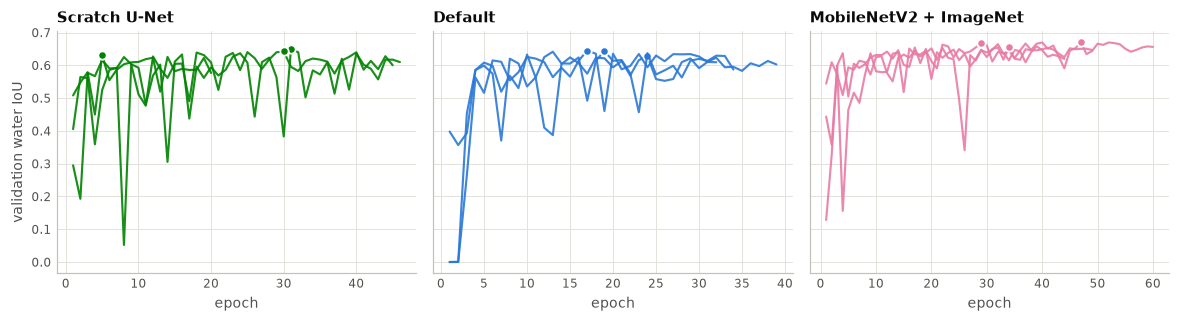

In [6]:
hist = {c: analysis.histories(runs_of(c)) for c in CONFIGS}
axes = viz.plot_val_curves(hist)
axes[0].figure.tight_layout()
viz.savefig(axes[0].figure, ROOT / "figures" / f"{STUDY}_val_curves.png")
plt.show()

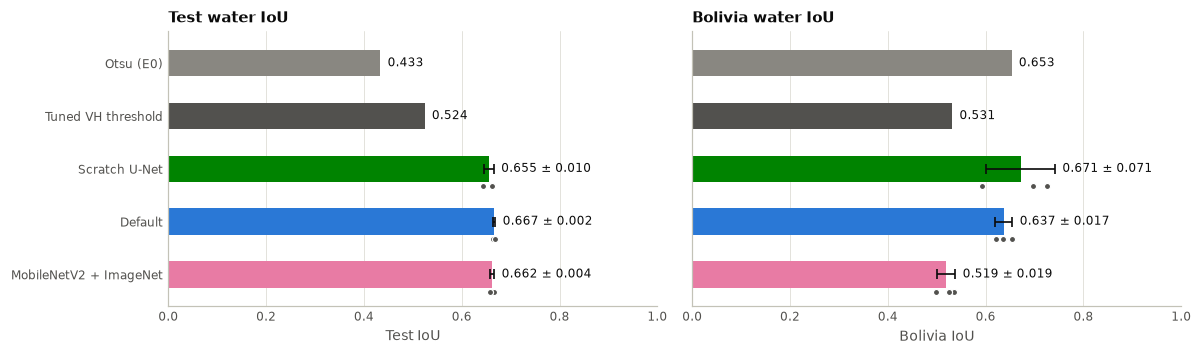

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3), sharey=True)
done = runs[runs["Status"] == "Finished"]
for ax, metric in zip(axes, ("Test IoU", "Bolivia IoU")):
    viz.plot_config_bars(done, CONFIGS, metric, ax, baseline=("Otsu (E0)", "Tuned VH threshold"))
    ax.set_title(metric.replace("IoU", "water IoU"))
fig.tight_layout()
viz.savefig(fig, ROOT / "figures" / f"{STUDY}_bars.png")
plt.show()

## 3. Cost of each encoder

Two sources:

* **logged by the real runs** (mean over the three seeds): epochs needed, seconds per epoch including validation, peak GPU memory and peak host RAM of the training process;
* **a controlled benchmark** (`src/benchmark.py`): each model alone on the GPU, 30 training steps on one fixed batch of 8 crops (256×256) and 30 predictions of 8 full chips (512×512), medians. The logged seconds per epoch depend on how warm and busy the laptop was during a run; the benchmark times all three models the same way. Each model is benchmarked three times after a warm-up call, and the table uses the median of the three. The warm-up matters: a process that has to compile the model first shows a peak GPU memory of about 1 GB instead of about 0.6 GB, which is compilation, not the model.

In [8]:
REPEATS = 3
bench_file = ROOT / "results" / "cost_benchmark_repeats.csv"
if bench_file.exists():
    repeats = pd.read_csv(bench_file)
else:
    rows = []
    for config in CONFIGS:
        encoder = load_config(runs_of(config)[0])["encoder"]
        run_benchmark(encoder=encoder)                       # warm-up: makes sure the compiled kernels are cached
        for i in range(REPEATS):
            rows.append({"Config": config, "repeat": i + 1, **run_benchmark(encoder=encoder)})
    repeats = pd.DataFrame(rows)
    repeats.to_csv(bench_file, index=False)
repeats[["Config", "repeat", "train_step_ms", "inference_ms_per_chip", "peak_gpu_memory_train_mb", "peak_gpu_memory_inference_mb",
         "first_train_step_s"]].set_index(["Config", "repeat"])

train_step_ms  inference_ms_per_chip  \
Config                 repeat                                         
Scratch U-Net          1             41.5000                 5.0000   
                       2             41.5000                 5.6000   
                       3             40.9000                 5.3000   
Default                1             55.9000                10.0000   
                       2             56.5000                 8.1000   
                       3             56.2000                 9.0000   
MobileNetV2 + ImageNet 1             58.0000                 9.9000   
                       2             56.8000                 6.5000   
                       3             57.9000                 6.4000   

                               peak_gpu_memory_train_mb  \
Config                 repeat                             
Scratch U-Net          1                       551.4000   
                       2                       551.4000   
                       3                       551.4000   
Default                1                       618.0000   
                       2                       618.0000   
                       3                       618.0000   
MobileNetV2 + ImageNet 1                       612.3000   
                       2                       612.3000   
                       3                       612.3000   

                               peak_gpu_memory_inference_mb  \
Config                 repeat                                 
Scratch U-Net          1                           346.3000   
                       2                           346.3000   
                       3                           346.3000   
Default                1                           372.0000   
                       2                           372.0000   
                       3                           372.0000   
MobileNetV2 + ImageNet 1                           369.7000   
                       2                           369.7000   
                       3                           369.7000   

                               first_train_step_s  
Config                 repeat                      
Scratch U-Net          1                   9.7000  
                       2                   9.7000  
                       3                   9.6000  
Default                1                  31.7000  
                       2                  32.5000  
                       3                  32.6000  
MobileNetV2 + ImageNet 1                  33.0000  
                       2                  33.5000  
                       3                  33.5000

In [9]:
bench = repeats.groupby("Config", sort=False)[["total_params", "train_step_ms", "inference_ms_per_chip",
                                               "peak_gpu_memory_train_mb", "peak_gpu_memory_inference_mb"]].median()
logged = done[done["Config"].isin(CONFIGS)].groupby("Config")[
    ["Epochs trained", "Sec per epoch", "Train minutes", "Peak host RAM (MB)"]].mean()
cost = pd.DataFrame({
    "Parameters (millions)": bench["total_params"].astype(float) / 1e6,
    "Training step (ms), benchmark": bench["train_step_ms"].astype(float),
    "Inference per chip (ms), benchmark": bench["inference_ms_per_chip"].astype(float),
    "Peak GPU memory, training (MB), benchmark": bench["peak_gpu_memory_train_mb"].astype(float),
    "Peak GPU memory, inference (MB), benchmark": bench["peak_gpu_memory_inference_mb"].astype(float),
    "Epochs trained, mean of 3 runs": logged["Epochs trained"],
    "Seconds per epoch, mean of 3 runs": logged["Sec per epoch"],
    "Training minutes per run, mean of 3 runs": logged["Train minutes"],
    "Peak host RAM (MB), mean of 3 runs": logged["Peak host RAM (MB)"],
}).loc[list(CONFIGS)]
cost.to_csv(ROOT / "results" / "cost_table.csv")
cost.T.round(2)

Config,Scratch U-Net,Default,MobileNetV2 + ImageNet
Parameters (millions),1.9700,5.4200,5.4200
"Training step (ms), benchmark",41.5000,56.2000,57.9000
"Inference per chip (ms), benchmark",5.3000,9.0000,6.5000
"Peak GPU memory, training (MB), benchmark",551.4000,618.0000,612.3000
"Peak GPU memory, inference (MB), benchmark",346.3000,372.0000,369.7000
"Epochs trained, mean of 3 runs",37.0000,35.0000,51.0000
"Seconds per epoch, mean of 3 runs",6.2800,8.5600,8.3900
"Training minutes per run, mean of 3 runs",4.5200,6.1700,9.0400
"Peak host RAM (MB), mean of 3 runs",3882.3300,4507.3300,4487.3300


## 4. Reading (RQ3)

**Accuracy.**

* **On the test chips the three encoders are within about one IoU point.** Scratch U-Net 0.655 ± 0.010, MobileNetV2 0.667 ± 0.002, MobileNetV2 with ImageNet weights 0.662 ± 0.004. The gap between the scratch U-Net and the default (0.011) is just larger than the spread between seeds, so by the project's rule it counts, but only just (t-test p = 0.20).
* **ImageNet weights help on validation, not on test, and hurt on Bolivia.** Validation IoU rises from 0.639 ± 0.009 to 0.664 ± 0.007. Test IoU does not move (0.662 against 0.667). On Bolivia the pretrained models drop to 0.519 ± 0.019, against 0.637 ± 0.017 for the same network trained from random weights: a gap of 0.118, six times the spread between seeds (p = 0.001). The pretrained encoder fits the ten floods it was trained on better and carries over to the eleventh worse.
* **The small scratch U-Net is the only model that keeps its level on Bolivia** (0.671 on average, against 0.655 on test), but it is also the least predictable there: 0.726, 0.696 and 0.592 for the three seeds. Its third seed stopped after 20 epochs on an early validation peak (best epoch 5) and is the weakest of the three everywhere.
* The scratch U-Net trades precision for recall compared with the MobileNetV2 models (precision 0.79 against 0.84, recall 0.79 against 0.77 on test).

**Cost** (see the table above for the numbers).

* **The scratch U-Net is the cheaper model on every count.** It has about a third of the parameters (1.97 against 5.42 million), a faster training step (about 41 ms against 56 ms), shorter runs (4.5 against 6.2 minutes) and a faster prediction (about 5 ms per chip against 6 to 10 ms).
* **GPU memory is not a constraint for any of them:** 0.55 to 0.62 GB in training and about 0.35 GB at prediction, on a 4 GB card.
* **The two MobileNetV2 models are the same network and should cost the same.** Their training steps agree (56 and 58 ms). Their prediction times differ (median 9.0 and 6.5 ms) only because that measurement is noisy: single repeats range from 6.4 to 10.0 ms. Prediction times are therefore good to about a third, not to the millisecond.
* ImageNet weights cost nothing at run time, but the pretrained runs needed more epochs before early stopping ended them (51 on average, against 35).